# 13 — Sky models against the power-law 408 MHz prediction along the TRIS ring (plots for Phil)

Three figures and one table, made **only from notebook 12's cache**, against the **power-law fit only**. This notebook runs no fits and
no limTOD; it reads:

* `model_comparison/sky_models_408/cache/sky_tods.npz`: each sky model at 408 MHz observed through the
  TRIS beam, per ring sample (CMB removed, Rayleigh–Jeans K), with its beam coverage;
* `cache/ring_RA.npy`: the RA of each ring sample (RA = LST);
* `cache/fits/unitNNN__power_law.npz`: the UltraNest power-law fit of the SED at each ring sample
  (TRIS 600/820 MHz, LWA 35/80, Maipu 45, Stockert 1420; **Haslam is not a fit point**). The pivot is
  408 MHz, so the fit's 408 MHz prediction is the amplitude `A_K`.

**Fit prediction** = the maximum-likelihood `A_K` (`maxpoint`); its 1σ is the standard deviation of
the posterior `A_K` samples. A sample is used when the model's beam coverage is ≥ 0.5, as in notebook 12.
**Residual** = model − fit, in K, and as a percentage of the fit, 100 (model − fit) / fit.

**χ²** = Σ (model − fit)² / σ_fit² over the valid ring samples, where σ_fit is the 1σ of the power law's
408 MHz prediction. The sky models carry no error bars of their own here, as in notebook 12.

Figures and the CSV go to `model_comparison/phil_plots/`. Rerun: Restart & Run All (seconds).

In [1]:
%matplotlib inline
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CACHE = REPO / "model_comparison" / "sky_models_408" / "cache"
OUT_DIR = REPO / "model_comparison" / "phil_plots"

COV_MIN = 0.5              # a sample is valid when the model's beam coverage >= this (notebook 12)
BEST_FIT = "maxlike"       # "maxlike" (maximum-likelihood A_K) or "median" (posterior median)
CYG_A_RA = 299.9           # deg

PL = "power law"
FIT_STYLE = dict(color="black", ls="-")

LEGACY = ["Haslam (uncorrected)", "GSM2008", "GSM2016", "LFSM"]
CORRECTED = ["Haslam, Carter correction", "Haslam, Irfan correction", "GSM2016, GINAN correction"]
REFERENCE = "Haslam (uncorrected)"
# Okabe-Ito (plus Tol's wine for the 7th), colourblind-safe; one colour per model in both figures.
# Corrected models are dashed as a second cue.
MODEL_STYLE = {
    "Haslam (uncorrected)":      dict(color="#E69F00", ls="-"),
    "GSM2008":                   dict(color="#0072B2", ls="-"),
    "GSM2016":                   dict(color="#D55E00", ls="-"),
    "LFSM":                      dict(color="#009E73", ls="-"),
    "Haslam, Carter correction": dict(color="#56B4E9", ls="--"),
    "Haslam, Irfan correction":  dict(color="#CC79A7", ls="--"),
    "GSM2016, GINAN correction": dict(color="#882255", ls="--"),
}

plt.rcParams.update({"figure.dpi": 110, "font.size": 12, "axes.titlesize": 13,
                     "axes.labelsize": 12, "legend.fontsize": 10, "figure.facecolor": "white"})
OUT_DIR.mkdir(exist_ok=True)

def save(fig, name):
    # Save a figure as PNG in OUT_DIR, then show it inline.
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()
    print(f"saved {(OUT_DIR / f'{name}.png').relative_to(REPO)}")

## Load the cache

In [2]:
RA = np.load(CACHE / "ring_RA.npy")
N = RA.size

z = np.load(CACHE / "sky_tods.npz", allow_pickle=False)
names = [str(n) for n in z["names"]]
T_SKY = {}
for i, n in enumerate(names):
    tod, cov = z[f"tod_{i}"], z[f"cov_{i}"]
    T_SKY[n] = np.where(cov >= COV_MIN, tod, np.nan)
assert set(LEGACY + CORRECTED) <= set(names), names
print("sky models:", names)

A_best, A_sig = np.full(N, np.nan), np.full(N, np.nan)
for u in range(N):
    p = CACHE / "fits" / f"unit{u:03d}__power_law.npz"
    if not p.exists():
        continue
    r = np.load(p, allow_pickle=False)
    iA = [str(x) for x in r["names"]].index("A_K")
    a = r["samples"][:, iA]
    A_best[u] = float(r["maxpoint"][iA]) if BEST_FIT == "maxlike" else float(np.median(a))
    A_sig[u] = float(np.std(a))
print(f"power law: {np.isfinite(A_best).sum()} of {N} samples; "
      f"median A(408) {np.nanmedian(A_best):.2f} K, median 1σ {np.nanmedian(A_sig):.2f} K")

def residuals(model):
    d = T_SKY[model] - A_best
    return d, 100 * d / A_best

sky models: ['Haslam (uncorrected)', 'Haslam, Carter correction', 'Haslam, Irfan correction', 'GSM2008', 'GSM2016', 'GSM2016, GINAN correction', 'LFSM']
power law: 120 of 120 samples; median A(408) 32.15 K, median 1σ 0.17 K


In [3]:
def ring_figure(models, title, name):
    fig, (ax, rk) = plt.subplots(2, 1, figsize=(13, 9.5), sharex=True,
                                 gridspec_kw=dict(height_ratios=[2.2, 1], hspace=0.08))
    ax.fill_between(RA, A_best - A_sig, A_best + A_sig, color="black", alpha=0.15, lw=0)
    ax.plot(RA, A_best, lw=2.2, **FIT_STYLE, label="SED fit: power law (±1σ band)")
    for n in models:
        ax.plot(RA, T_SKY[n], lw=1.5, **MODEL_STYLE[n], label=n)
    ax.set_ylabel("T(408 MHz) − T_CMB [K, RJ]")

    rk.fill_between(RA, -A_sig, A_sig, color="0.85", lw=0, label="fit ±1σ")
    rk.axhline(0, color="0.3", lw=0.8)
    for n in models:
        dk, _ = residuals(n)
        rk.plot(RA, dk, lw=1.4, **MODEL_STYLE[n])
    rk.set_ylabel("model − power law\n[K]")
    rk.set_xlabel("RA = LST on the TRIS ring [deg]")
    for a in (ax, rk):
        a.axvline(CYG_A_RA, color="0.2", ls=":", lw=1, label=f"Cygnus A (RA {CYG_A_RA:g}°)" if a is ax else None)
        a.grid(alpha=0.25)
    rk.set_xlim(-3, 360); rk.set_xticks(np.arange(0, 361, 60))
    ax.legend(ncol=2, frameon=False, loc="upper left", fontsize=10)
    rk.legend(frameon=False, loc="lower left", fontsize=9)
    ax.set_title(title, fontsize=14)
    save(fig, name)

### Plot 1 — legacy sky models against the fitted 408 MHz sky
**Top:** the black line is the 408 MHz temperature the power-law SED fit predicts from the other surveys,
with its ±1σ band; the coloured lines are Haslam, GSM2008, GSM2016 and LFSM through the TRIS beam.
**Below:** model − power law in K; the grey band is the fit's own ±1σ, so a line inside it agrees with the fit.
The dotted vertical line marks Cygnus A.

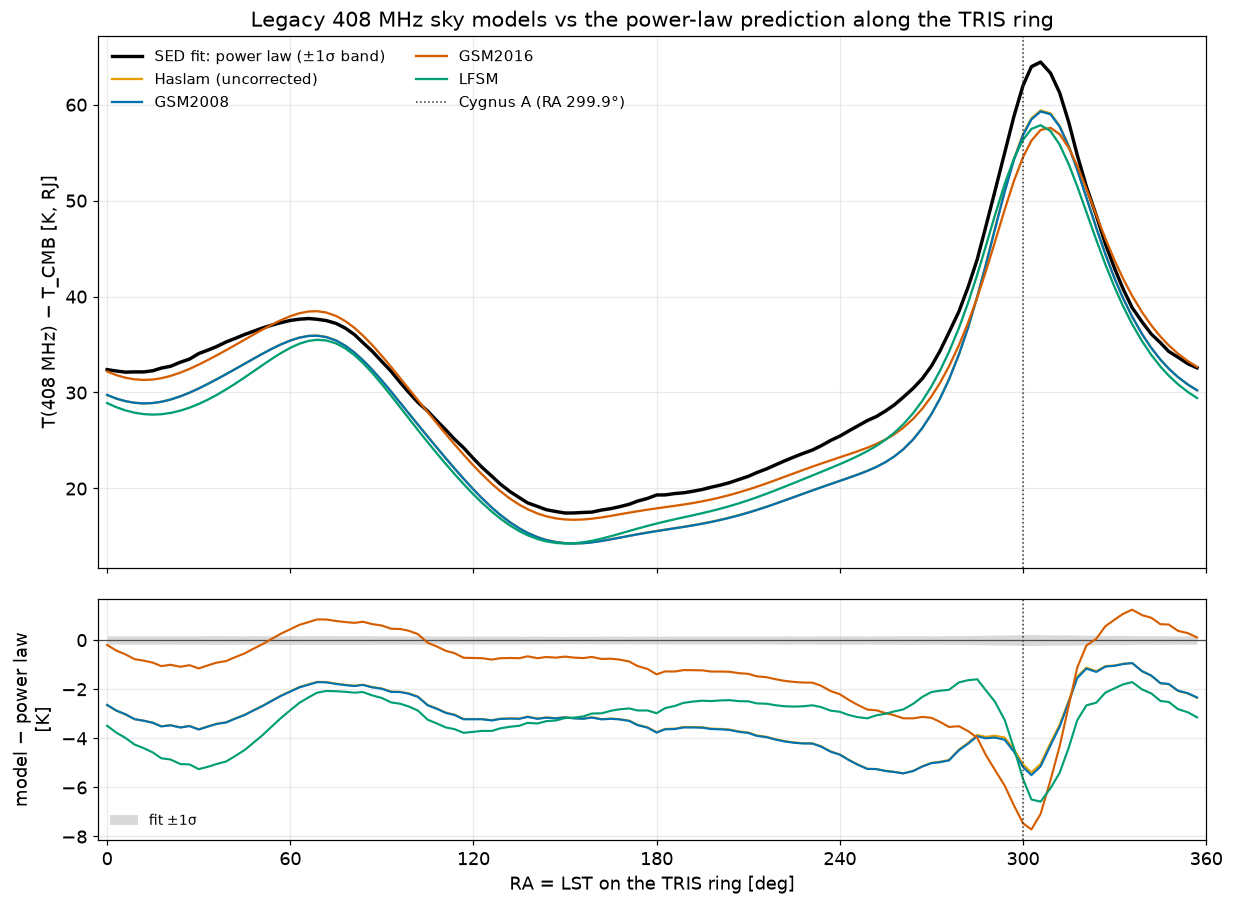

saved model_comparison/phil_plots/plot1_legacy_models_vs_fit.png


In [4]:
ring_figure(
    LEGACY,
    "Legacy 408 MHz sky models vs the power-law prediction along the TRIS ring",
    "plot1_legacy_models_vs_fit")

### Plot 2 — corrected sky models against the fitted 408 MHz sky
Same layout as Plot 1, for Haslam with the Carter and Irfan corrections and GSM2016 with the GINAN
correction (dashed), with uncorrected Haslam (solid orange) as the reference line. The GINAN
correction is only valid for 60–350 MHz; its 408 MHz map was built at 350 MHz and carried to 408 MHz
with GSM2016's own per-pixel ratio, so it is an extrapolation.

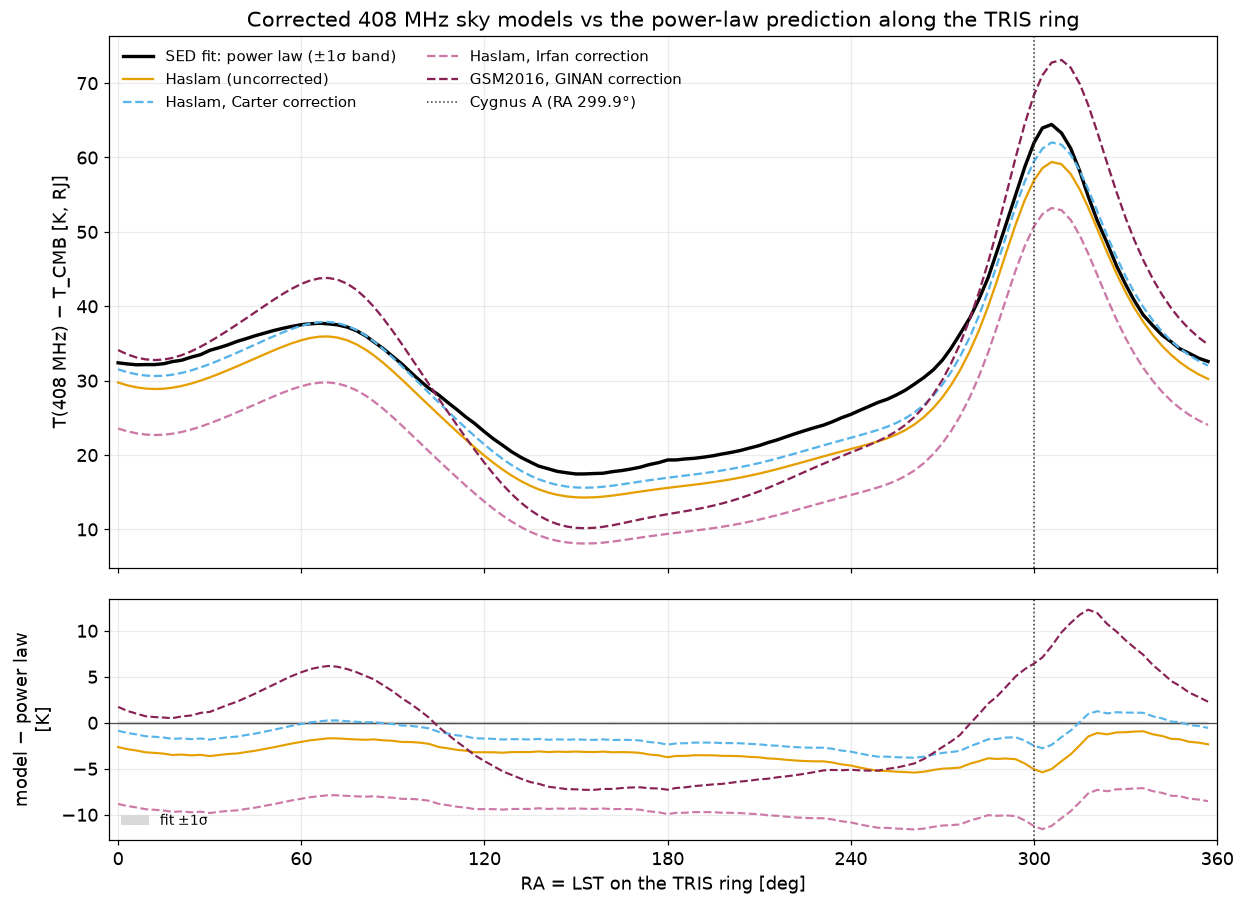

saved model_comparison/phil_plots/plot2_corrected_models_vs_fit.png


In [5]:
ring_figure(
    [REFERENCE] + CORRECTED,
    "Corrected 408 MHz sky models vs the power-law prediction along the TRIS ring",
    "plot2_corrected_models_vs_fit")

## Residual statistics and χ² per model

For each model, against the power-law prediction: the median and the rms (√mean of the square) of model − fit over the
valid ring samples, in K and in %, and χ² = Σ (model − fit)² / σ_fit². The rms includes the mean offset, so it measures
the total disagreement. χ²/N is the mean squared residual in units of the fit's 1σ (N = valid samples).

In [6]:
CHI_SAMPLE = {}
rows = []
for n in LEGACY + CORRECTED:
    dk, dp = residuals(n)
    ok = np.isfinite(dk) & np.isfinite(A_sig) & (A_sig > 0)
    CHI_SAMPLE[n] = np.where(ok, (dk / A_sig) ** 2, np.nan)
    chi2 = float(np.nansum(CHI_SAMPLE[n]))
    rows.append({"model": n, "group": "legacy" if n in LEGACY else "corrected", "N samples": int(ok.sum()),
                 "median residual [K]": float(np.median(dk[ok])), "rms residual [K]": float(np.sqrt(np.mean(dk[ok] ** 2))),
                 "median residual [%]": float(np.median(dp[ok])), "rms residual [%]": float(np.sqrt(np.mean(dp[ok] ** 2))),
                 "chi2": chi2, "chi2 / N": chi2 / ok.sum()})
stats = pd.DataFrame(rows)
stats["rank by chi2"] = stats["chi2"].rank().astype(int)
stats.to_csv(OUT_DIR / "residual_stats.csv", index=False)
print(f"saved {(OUT_DIR / 'residual_stats.csv').relative_to(REPO)}  (residual = model − power law; best fit = {BEST_FIT})\n")
with pd.option_context("display.width", 200):
    print(stats.sort_values("chi2").round(2).to_string(index=False))

saved model_comparison/phil_plots/residual_stats.csv  (residual = model − power law; best fit = maxlike)

                    model     group  N samples  median residual [K]  rms residual [K]  median residual [%]  rms residual [%]      chi2  chi2 / N  rank by chi2
                  GSM2016    legacy        120                -0.82              2.23                -3.80              5.84  16077.34    133.98             1
Haslam, Carter correction corrected        120                -1.77              1.96                -5.33              7.77  16100.47    134.17             2
                     LFSM    legacy        120                -2.88              3.33               -11.49             11.77  44207.90    368.40             3
     Haslam (uncorrected)    legacy        120                -3.22              3.44               -10.63             13.06  48562.80    404.69             4
                  GSM2008    legacy        120                -3.23              3.46              

### Plot 3 — χ² of each sky model against the power-law prediction
**Left:** each model's contribution to χ² at every ring sample, (model − fit)² / σ_fit², on a log scale, so you can see
where along the ring the disagreement comes from. **Right:** χ²/N per model, shortest bar best; legacy models solid,
corrected models hatched; the values are in the table above. The power law's σ_fit is small (median 0.17 K), so the χ² values are large: read the ranking,
not the absolute size.

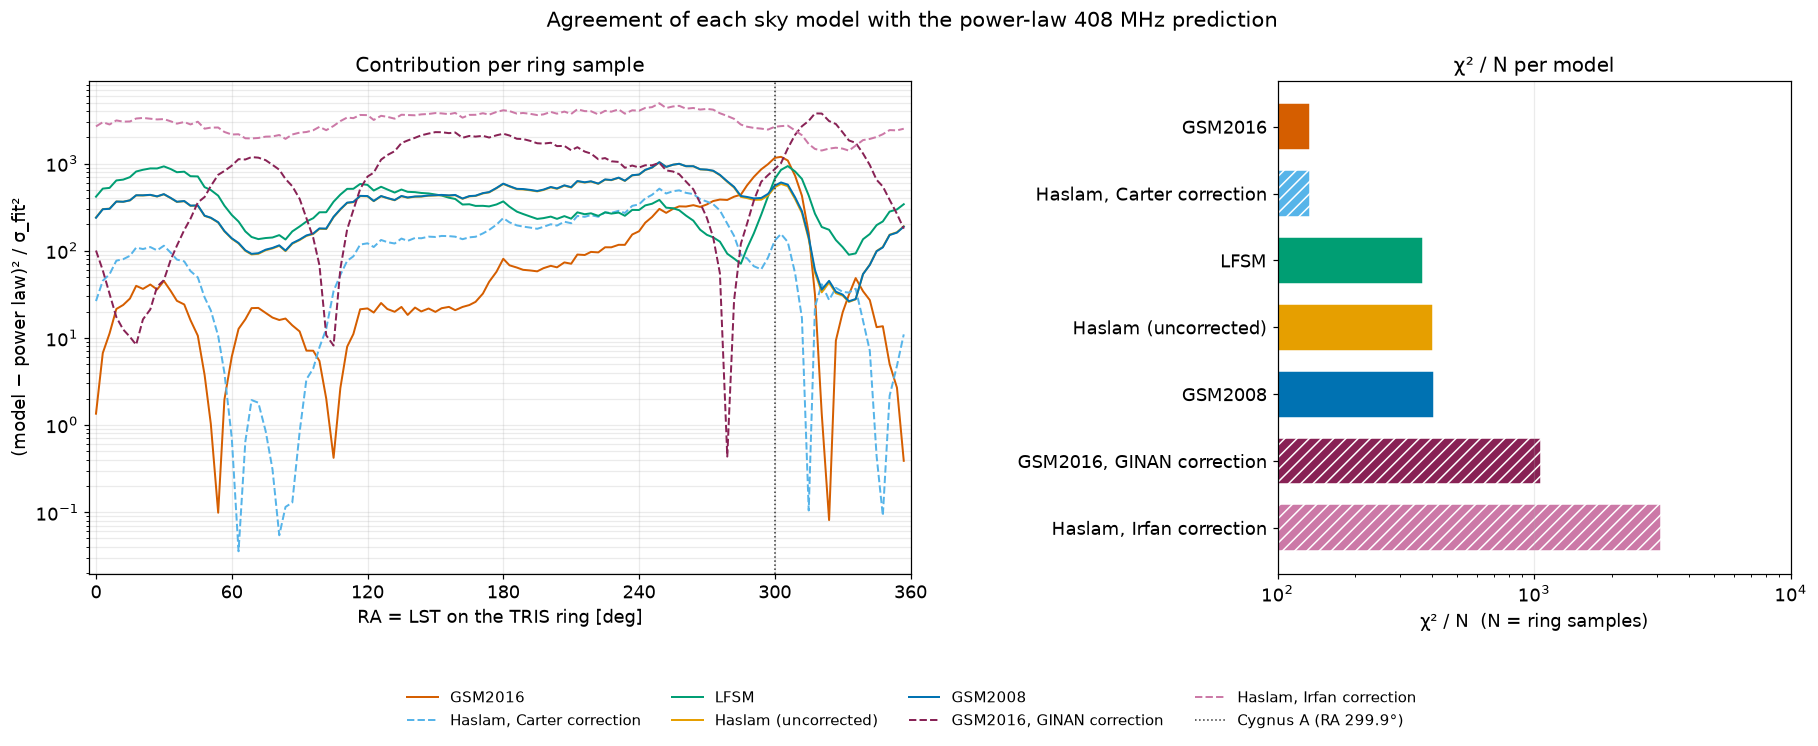

saved model_comparison/phil_plots/plot3_chi2_vs_power_law.png


In [7]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(17, 6.4), gridspec_kw=dict(width_ratios=[1.6, 1], wspace=0.55))
order = list(stats.sort_values("chi2")["model"])
for n in order:
    a1.plot(RA, CHI_SAMPLE[n], lw=1.3, **MODEL_STYLE[n], label=n)
a1.set_yscale("log")
a1.axvline(CYG_A_RA, color="0.2", ls=":", lw=1, label=f"Cygnus A (RA {CYG_A_RA:g}°)")
a1.set_xlim(-3, 360); a1.set_xticks(np.arange(0, 361, 60))
a1.set_xlabel("RA = LST on the TRIS ring [deg]"); a1.set_ylabel("(model − power law)² / σ_fit²")
a1.set_title("Contribution per ring sample"); a1.grid(alpha=0.25, which="both")

y = np.arange(len(order))[::-1]
st = stats.set_index("model")
for yi, n in zip(y, order):
    a2.barh(yi, st.loc[n, "chi2 / N"], color=MODEL_STYLE[n]["color"], height=0.7,
            hatch="///" if n in CORRECTED else None, edgecolor="white")
a2.set_xscale("log"); a2.set_yticks(y); a2.set_yticklabels(order)
from matplotlib.ticker import NullFormatter
a2.xaxis.set_minor_formatter(NullFormatter())
a2.set_xlim(10 ** np.floor(np.log10(stats["chi2 / N"].min())), 10 ** np.ceil(np.log10(stats["chi2 / N"].max())))
a2.set_xlabel("χ² / N  (N = ring samples)"); a2.set_title("χ² / N per model"); a2.grid(alpha=0.25, axis="x")
fig.legend(*a1.get_legend_handles_labels(), loc="lower center", ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.06))
fig.suptitle("Agreement of each sky model with the power-law 408 MHz prediction", fontsize=14)
fig.subplots_adjust(left=0.06, right=0.97, top=0.88, bottom=0.18)
save(fig, "plot3_chi2_vs_power_law")

## Summary

Against the power-law prediction only; residual = model − power law, over all 120 ring samples (`residual_stats.csv`).

| model | median [K] | rms [K] | median [%] | rms [%] | χ²/N |
|---|---|---|---|---|---|
| GSM2016 | −0.82 | 2.23 | −3.8 | 5.8 | 134.0 |
| Haslam, Carter correction | −1.77 | 1.96 | −5.3 | 7.8 | 134.2 |
| LFSM | −2.88 | 3.33 | −11.5 | 11.8 | 368 |
| Haslam (uncorrected) | −3.22 | 3.44 | −10.6 | 13.1 | 405 |
| GSM2008 | −3.23 | 3.46 | −10.7 | 13.1 | 408 |
| GSM2016, GINAN correction | +0.52 | 5.63 | +1.6 | 21.8 | 1059 |
| Haslam, Irfan correction | −9.41 | 9.50 | −29.5 | 36.0 | 3108 |

* **GSM2016 and the Carter-corrected Haslam agree best** with the power-law prediction, effectively tied in χ²
  (134.0 and 134.2 per sample). Carter has the smaller rms (1.96 K against 2.23 K), GSM2016 the smaller median offset.
* **Every model except GINAN is colder than the power-law prediction** along almost the whole ring.
* **GINAN** has the smallest median offset (+0.5 K) but a large rms (5.6 K): too bright near RA ≈ 70° and 300–340°,
  too faint between RA ≈ 120° and 260°. Its 408 MHz map is an extrapolation of a correction valid only to 350 MHz.
* **Haslam, GSM2008 and LFSM** nearly coincide (GSM2008's line sits on Haslam's in Plot 3).
* **The Irfan correction** removes the full 8.9 K monopole (CMB + radio background + 21 cm), so it is lowest by construction.
* **χ² is large for every model** because the power law's 408 MHz prediction is tight (median σ 0.17 K) and the sky
  models carry no errors here; the ranking is what matters. Plot 3 (left) shows the disagreement comes from the whole
  ring, not only Cygnus.
